# Q-Learning sur FrozenLake

**Projet :** Eagle-1 - pilote automatique d'atterrissage lunaire (AstroDynamics)  
**Étape :** Exercice 2 - Entraînez un agent avec une table de décision (Q-table)  
**Auteur :** Kilian Lefevre

---

## Objectif du notebook

Ce notebook implémente de zéro le Q-Learning sur l'environnement `FrozenLake-v1` de Gymnasium. Il répond aux questions suivantes :

- Comment représenter ce que l'agent a appris sous la forme d'une table (Q-table) ?
- Comment l'agent arbitre-t-il entre explorer et exploiter (stratégie epsilon-greedy) ?
- Quel taux de réussite obtient la Q-table apprise sur 1 000 épisodes d'évaluation ?

Contrairement à `CartPole`, `FrozenLake` a un nombre **fini** d'états : c'est ce qui rend possible une Q-table.

In [1]:
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np

from rl_pilot.config import SEED

print(f"gymnasium {gym.__version__}")

gymnasium 1.4.0


## 1. Environnement et Q-table

### 1.1 Création de l'environnement

`FrozenLake-v1` est une grille 4×4 de glace : l'agent part de la case de départ `S` (en haut à gauche) et doit atteindre l'arrivée `G` (en bas à droite) sans tomber dans un trou `H`.

```text
S F F F
F H F H
F F F H
H F F G
```

| Élément | Valeur |
|---|---|
| Observation | `Discrete(16)` : le numéro de la case, `ligne * 4 + colonne` (de 0 à 15) |
| Actions | `Discrete(4)` : `0` gauche, `1` bas, `2` droite, `3` haut |
| Récompense | `+1` à l'arrivée, `0` partout ailleurs |
| Fin d'épisode | chute dans un trou ou arrivée (`terminated`), ou 100 pas (`truncated`) |

Deux différences avec `CartPole` :

- l'observation est un entier parmi 16 : le nombre d'états est **fini**, ce qui rend possible une Q-table ;
- la récompense est **rare** : l'agent ne reçoit rien tant qu'il n'a pas atteint l'arrivée.

La glace est **glissante** (`is_slippery=True` par défaut) : l'agent va dans la direction choisie avec la probabilité 1/3, et dans chacune des deux directions perpendiculaires avec la probabilité 1/3. Une même action peut donc mener à des cases différentes.

Discrete(4)

np.int64(2)

Discrete(16)

np.int64(9)

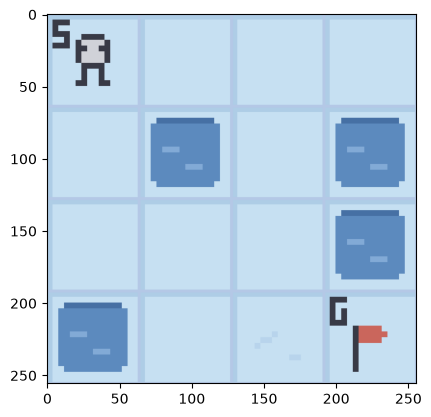

In [2]:
env = gym.make("FrozenLake-v1", render_mode="rgb_array")

env.reset()
plt.imshow(env.render())  # type: ignore

display(env.action_space, env.action_space.sample())
display(env.observation_space, env.observation_space.sample())

### 1.2 Initialisation de la Q-table

La Q-table associe à chaque paire `(état, action)` une valeur Q : le gain total que l'agent espère obtenir en jouant cette action dans cet état. Elle a donc **une ligne par état et une colonne par action**, soit `(16, 4)`, dimensions obtenues avec `env.observation_space.n` et `env.action_space.n`. Au départ elle est remplie de zéros : l'agent ne sait encore rien.

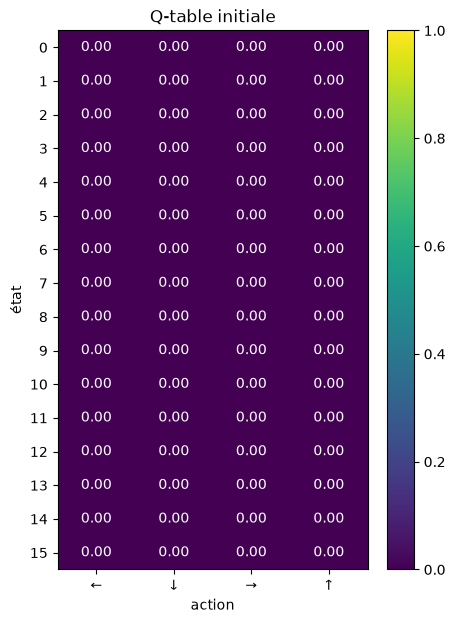

In [3]:
Q_table = np.zeros(shape=(env.observation_space.n, env.action_space.n))

ARROWS = np.array(["←", "↓", "→", "↑"])


def plot_q_table(q_table, title):
    """Affiche la Q-table en heatmap : un état par ligne, une action par colonne."""
    fig, ax = plt.subplots(figsize=(5, 7))
    # Les valeurs Q sont comprises entre 0 et 1 (la récompense maximale est 1)
    image = ax.imshow(q_table, cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(q_table.shape[1]), ARROWS)
    ax.set_yticks(range(q_table.shape[0]))
    ax.set_xlabel("action")
    ax.set_ylabel("état")
    ax.set_title(title)
    for state, action in np.ndindex(q_table.shape):
        value = q_table[state, action]
        color = "black" if value > 0.5 else "white"
        ax.text(
            action, state, f"{value:.2f}", ha="center", va="center", color=color
        )
    fig.colorbar(image, ax=ax)
    plt.show()


plot_q_table(Q_table, "Q-table initiale")

## 2. Entraînement

### 2.1 Hyperparamètres

| Réglage | Valeur | Rôle |
|---|--:|---|
| `LEARNING_RATE` | 0.1 | Part de l'erreur de prédiction appliquée à chaque mise à jour. Une valeur faible lisse le bruit dû à la glace glissante. |
| `DISCOUNT_FACTOR` | 0.99 | Poids des récompenses futures. Il doit être élevé : la seule récompense (1.0) est à l'arrivée et doit se propager jusqu'aux états de départ. |
| `EPSILON_START` | 1.0 | Probabilité d'explorer au départ : la Q-table est vide, l'agent joue au hasard. |
| `EPSILON_MIN` | 0.05 | Plancher d'exploration : l'agent explore encore un peu à la fin. |
| `EPSILON_DECAY` | 0.9996 | `epsilon` est multiplié par ce facteur à chaque épisode. Il atteint son plancher après environ 7 500 épisodes, soit les trois quarts de l'entraînement. |
| `N_EPISODES` | 10 000 | Nombre d'épisodes d'entraînement. |

Ces valeurs sont un point de départ à ajuster d'après le taux de réussite de la partie 3.

In [4]:
LEARNING_RATE = 0.1
DISCOUNT_FACTOR = 0.99

EPSILON_START = 1.0
EPSILON_MIN = 0.05
EPSILON_DECAY = 0.9996

N_EPISODES = 10_000

### 2.2 Boucle de Q-Learning

À chaque pas de temps :

1. **Choisir l'action** (stratégie epsilon-greedy) : avec la probabilité `epsilon`, l'agent **explore** (action aléatoire), sinon il **exploite** (`np.argmax` de la ligne de la Q-table pour l'état courant).
2. **Jouer l'action** avec `env.step(action)`.
3. **Mettre à jour la paire `(state, action)`** avec la formule de Bellman :

   `nouvelle_valeur = ancienne_valeur + LEARNING_RATE * (reward + DISCOUNT_FACTOR * max_q_future - ancienne_valeur)`

   où `max_q_future = np.max(Q_table[new_state, :])` est la meilleure valeur connue depuis l'état d'arrivée.

À la fin de chaque épisode, `epsilon` diminue : l'agent explore de moins en moins à mesure qu'il apprend.

Points d'attention :

- `max_q_future` se lit sur `new_state`, mais la mise à jour s'applique à la paire `(state, action)` qui vient d'être jouée.
- Les états terminaux (trous et arrivée) ne sont jamais quittés : leur ligne reste à `0`, donc `max_q_future` y vaut `0`.
- La Q-table est remise à zéro au début de la cellule : on peut la relancer sans cumuler les entraînements. `SEED` initialise le tirage d'exploration, les actions aléatoires et le premier `reset`.

In [5]:
rng = np.random.default_rng(SEED)
env.action_space.seed(SEED)

Q_table[:] = 0
epsilon = EPSILON_START
episode_rewards = []

for episode in range(N_EPISODES):
    state, info = env.reset(seed=SEED + episode)
    terminated = truncated = False
    total_reward = 0.0

    while not (terminated or truncated):
        if rng.random() < epsilon:
            action = env.action_space.sample()  # exploration
        else:
            action = int(np.argmax(Q_table[state, :]))  # exploitation

        new_state, reward, terminated, truncated, info = env.step(action)

        old_value = Q_table[state, action]
        max_q_future = np.max(Q_table[new_state, :])
        Q_table[state, action] = old_value + LEARNING_RATE * (
            reward + DISCOUNT_FACTOR * max_q_future - old_value  # type: ignore
        )

        state = new_state
        total_reward += reward  # type: ignore

    epsilon = max(EPSILON_MIN, epsilon * EPSILON_DECAY)
    episode_rewards.append(total_reward)

print(f"Épisodes gagnés pendant l'entraînement : {int(sum(episode_rewards))}")
print(f"epsilon final : {epsilon:.3f}")

Épisodes gagnés pendant l'entraînement : 3044
epsilon final : 0.050


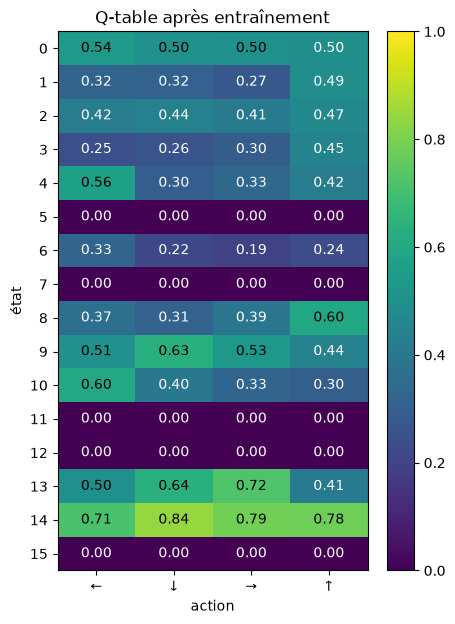

In [6]:
plot_q_table(Q_table, "Q-table après entraînement")

## 3. Évaluation

### 3.1 Taux de réussite

On évalue maintenant la Q-table **figée** : la phase d'apprentissage est terminée.

- l'agent joue toujours `np.argmax(Q_table[state, :])` : plus d'exploration, donc plus d'epsilon ;
- la Q-table n'est **pas modifiée** (aucune mise à jour de Bellman) ;
- 1 000 épisodes (`N_EPISODES_TEST`), avec des graines (`SEED + N_EPISODES + episode`) différentes de celles de l'entraînement ;
- une victoire est un épisode de récompense `1.0` (l'arrivée est atteinte) : le taux de réussite est le nombre de victoires divisé par `N_EPISODES_TEST`.

In [7]:
N_EPISODES_TEST = 1000
episode_rewards_test = []

for episode in range(N_EPISODES_TEST):
    state, info = env.reset(seed=SEED + N_EPISODES + episode)
    terminated = truncated = False
    total_reward = 0.0

    while not (terminated or truncated):
        action = int(np.argmax(Q_table[state, :]))  # exploitation

        new_state, reward, terminated, truncated, info = env.step(action)

        state = new_state
        total_reward += reward  # type: ignore

    episode_rewards_test.append(total_reward)

print(f"Épisodes gagnés pendant le test : {int(sum(episode_rewards_test))}")
print(
    f"Taux de victoire pendant les tests : {100 * sum(episode_rewards_test) / N_EPISODES_TEST}%"
)

Épisodes gagnés pendant le test : 734
Taux de victoire pendant les tests : 73.4%


### 3.2 Politique apprise

La politique apprise est l'action de plus grande valeur dans chaque état. On l'affiche sur la grille (`■` : trous et arrivée, états terminaux dont la ligne reste à `0`) :

In [8]:
best_actions = np.argmax(Q_table, axis=1)
is_visited = Q_table.any(axis=1)

policy = np.where(is_visited, ARROWS[best_actions], "■").reshape(4, 4)
for row in policy:
    print(" ".join(row))

← ↑ ↑ ↑
← ■ ← ■
↑ ↓ ← ■
■ → ↓ ■


## 4. Conclusion

- **Ce que contient la Q-table :** une table `(16, 4)` de 64 valeurs, apprise en 10 000 épisodes. Les lignes des états terminaux (les trous et l'arrivée) restent à `0`, puisque l'agent n'en repart jamais. Les valeurs sont les plus élevées près de l'arrivée (environ 0,84 dans l'état 14) et diminuent en s'en éloignant (environ 0,54 au départ), avec `SEED = 42`.
- **Politique apprise :** elle ne fonce pas vers l'arrivée, elle cherche à **minimiser le risque de chute**. Depuis la case de départ par exemple, elle pousse vers la gauche, contre le mur : sur la glace glissante, cette action ne peut jamais mener vers la droite ni dans un trou.
- **Taux de réussite :** 734 victoires sur 1 000 épisodes d'évaluation (73,4 %), contre environ 30 % pendant l'entraînement (3 044 victoires sur 10 000 épisodes), où l'agent explorait encore. Avec 1 000 épisodes, ce taux est connu à ±3 points environ (intervalle à 95 %), mais il vient d'un seul entraînement avec une seule graine.

**Limites de la méthode**

- **Un taux de 100 % est hors de portée.** À cause de la glace glissante, même une politique optimale peut glisser dans un trou : la Q-table ne peut pas supprimer le hasard de l'environnement.
- **La Q-table ne passe pas à l'échelle.** 16 états × 4 actions tiennent dans un tableau, mais `CartPole` a une observation continue de 4 nombres : il faudrait la découper en intervalles (avec perte d'information) ou approximer la fonction Q par un réseau de neurones, ce que fait le DQN de l'exercice 3.
- **Les résultats dépendent des hyperparamètres.** Pour s'en rendre compte, on peut faire varier `DISCOUNT_FACTOR` (par exemple `0.95`), `LEARNING_RATE` ou `N_EPISODES`, et comparer les taux de réussite, si possible avec plusieurs graines.